# P3.07 — Portugal against its peers: prices, property tax and housing spending

**Question:** RQ6.5 (how do other European countries' housing policies compare, and which could transfer to Portugal?), partly.

Three comparable national indicators for Portugal, Spain, Italy, France, Germany and Ireland: the change in the house price index
2015 to 2024 (nominal), the recurrent property tax (national accounts D29A, taxes on land, buildings and other structures) and
housing support (`p3_06`: housing development plus housing allowances), the last two as a share of GDP averaged over 2015-2024.
Transfer taxes are left out because countries book them under different codes (Germany's is 0.00% of GDP in D214C). What these
data do **not** hold is the policies themselves (rent regulation, tenant protection, planning, public-housing stock), so this
compares how much countries tax and spend, not which instruments they use. Six countries cannot support an inference: the table
and chart are a comparison, not a test of what lowers prices.

In [1]:
from pthousing.analysis import peers
from pthousing.data import interim
from pthousing.viz import charts, style

style.apply_style()
mix = peers.policy_mix(
    interim.read("eurostat_hpi"),
    interim.read("eurostat_property_tax_peers"),
    interim.read("eurostat_housing_spending"),
    start=2015,
    end=2024,
    exclude_spending=("IT", "EU27_2020"),
)
mix.round(2)

,price_change_pct,property_tax_gdp_pct,housing_support_gdp_pct
geo,,,
DE,47.99,0.40,0.48
ES,60.25,1.07,0.20
EU27_2020,53.42,1.02,NaN
FR,26.39,2.44,1.19
IE,83.37,0.48,0.94
IT,11.70,1.18,NaN
PT,124.44,0.75,0.41


## Step 1 — The three indicators
Sorted by price change. Italy has no housing-support value: its 2022-2023 spending is far above trend (probably renovation tax
credits booked as expenditure, see `p3_06`).

,price_change_pct,property_tax_gdp_pct,housing_support_gdp_pct
geo,,,
PT,124.44,0.75,0.41
IE,83.37,0.48,0.94
ES,60.25,1.07,0.20
DE,47.99,0.40,0.48
FR,26.39,2.44,1.19
IT,11.70,1.18,NaN


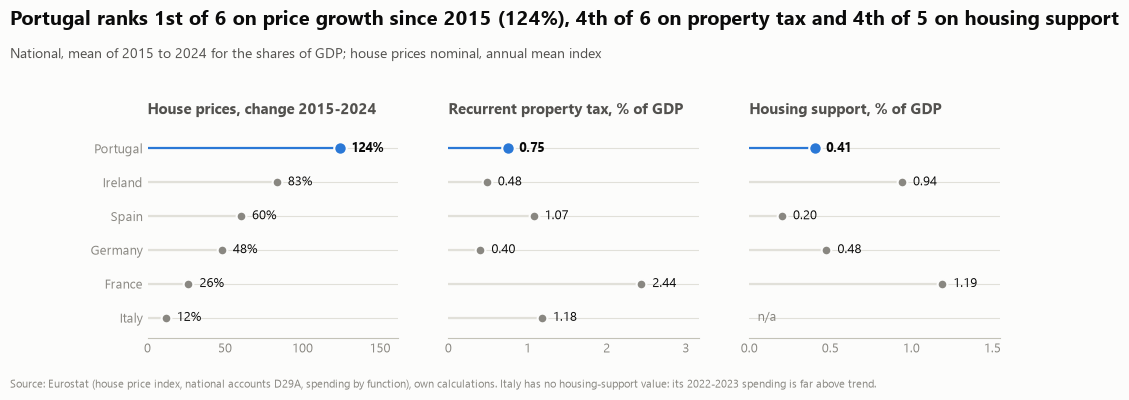

In [2]:
names = {
    "PT": "Portugal",
    "ES": "Spain",
    "IT": "Italy",
    "FR": "France",
    "DE": "Germany",
    "IE": "Ireland",
}
fig = charts.peers_policy_mix(mix, names)
style.save_fig(fig, "p3", "peer_policy_mix")
style.save_table(mix.round(2).reset_index(), "p3", "peer_policy_mix")
mix.loc[list(names)].sort_values("price_change_pct", ascending=False).round(2)

## Step 2 — How far apart are they over the years?
The recurrent property tax as a share of GDP for the six countries at five dates.

In [3]:
tax = interim.read("eurostat_property_tax_peers")
tax_share = (
    100
    * tax.set_index(["geo", "year"])["land_buildings_tax_eur_m"]
    / tax.set_index(["geo", "year"])["gdp_eur_m"]
).unstack("geo")
over_time = tax_share.loc[[2000, 2007, 2013, 2019, 2024], ["PT", "ES", "IT", "FR", "DE", "IE"]]
style.save_table(over_time.round(2).reset_index(), "p3", "recurrent_property_tax_gdp")
over_time.round(2)

geo,PT,ES,IT,FR,DE,IE
year,,,,,,
2000,0.40,0.62,0.68,2.58,0.42,0.54
2007,0.58,0.68,0.74,2.51,0.42,0.63
2013,0.79,1.15,1.22,2.51,0.43,0.93
2019,0.80,1.08,1.17,2.62,0.41,0.52
2024,0.58,0.89,1.02,2.09,0.37,0.40


## Key numbers

In [4]:
m = mix.loc[list(names)]
pt = m.loc["PT"]
print(
    "price change 2015-2024: "
    + ", ".join(
        f"{names[g]} {v:+.0f}%"
        for g, v in m["price_change_pct"].sort_values(ascending=False).items()
    )
)
print(
    "recurrent property tax, mean % of GDP: "
    + ", ".join(
        f"{names[g]} {v:.2f}"
        for g, v in m["property_tax_gdp_pct"].sort_values(ascending=False).items()
    )
)
print(
    "housing support, mean % of GDP: "
    + ", ".join(
        f"{names[g]} {v:.2f}"
        for g, v in m["housing_support_gdp_pct"].dropna().sort_values(ascending=False).items()
    )
)
print(
    f"Portugal: prices {pt.price_change_pct:+.0f}% (peer median {m.drop('PT')['price_change_pct'].median():+.0f}%), property tax {pt.property_tax_gdp_pct:.2f}% of GDP "
    f"(peer median {m.drop('PT')['property_tax_gdp_pct'].median():.2f}%), housing support {pt.housing_support_gdp_pct:.2f}% (peer median {m.drop('PT')['housing_support_gdp_pct'].median():.2f}%)"
)
print(
    "property tax over time (PT): "
    + ", ".join(f"{y} {over_time.loc[y, 'PT']:.2f}%" for y in over_time.index)
)

price change 2015-2024: Portugal +124%, Ireland +83%, Spain +60%, Germany +48%, France +26%, Italy +12%
recurrent property tax, mean % of GDP: France 2.44, Italy 1.18, Spain 1.07, Portugal 0.75, Ireland 0.48, Germany 0.40
housing support, mean % of GDP: France 1.19, Ireland 0.94, Germany 0.48, Portugal 0.41, Spain 0.20
Portugal: prices +124% (peer median +48%), property tax 0.75% of GDP (peer median 1.07%), housing support 0.41% (peer median 0.71%)
property tax over time (PT): 2000 0.40%, 2007 0.58%, 2013 0.79%, 2019 0.80%, 2024 0.58%
